# Forecasting next month's water storage with a TCN

In this notebook we train a Temporal Convolutional Network (TCN) to predict next month's water storage
(TWS anomaly, in cm) for every land cell in our shared dataset, and test whether adding weather data
helps. The model code is in `scripts/tcn_forecast.py` and all settings are in `configs/tcn_config.yaml`.


**The four models we compare.** The first is a **GRACE-only TCN**, which predicts next month's water
storage from past storage alone. The second is an **early-fusion TCN**, which gets past water storage,
precipitation and temperature all at once and learns from them together in a single network. The third
is a **P,T-only TCN**, which sees only precipitation and temperature. We don't use it as a forecaster on
its own; it serves as the second branch for late fusion. The fourth is a **late-fusion model**, which takes
the forecasts from the GRACE-only and P,T-only models and blends them with a weighted average, using
weights learned on 2023 data.


**How we train and test.** We follow the same steps as the baselines:
1. Train on 2019–2022.
2. Try 12 hyperparameter settings and keep the one that does best on 2023.
3. Retrain that setting on 2019–2023.
4. Score it once on the test period (2024-01 to 2025-09), using exactly the same cells as the baselines.

At the end, we also check whether the weather inputs make a real difference (Section 10) and which inputs
the model relies on most (Section 11).

In [1]:
# Parameters (papermill can override these). QUICK_RUN trains a tiny grid for a fast end-to-end check.
QUICK_RUN = False

In [2]:
from pathlib import Path
import json
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import xarray as xr
from IPython.display import display


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "scripts" / "tcn_forecast.py").is_file():
            return candidate
    raise FileNotFoundError("Run the notebook from inside a clone of the repository.")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

import p_t_tws_data as alignment
import tcn_forecast as tcn
from grace_fo_processing import compressed_float_encoding
from p_t_tws_analysis import save_figure

%matplotlib inline
warnings.filterwarnings("ignore", category=RuntimeWarning)
print("PyTorch", torch.__version__, "| CUDA:", torch.cuda.is_available(), "| CPU threads:", torch.get_num_threads())

PyTorch 2.2.2 | CUDA: False | CPU threads: 8


## 1. Configuration

In [3]:
CONFIG_PATH = PROJECT_ROOT / "configs" / "tcn_config.yaml"
ALIGNED_FILE = PROJECT_ROOT / "data" / "processed" / "p_t_tws_aligned_0.5deg.nc"
BASELINE_PREDICTIONS = PROJECT_ROOT / "data" / "processed" / "p_t_tws_baseline_predictions.nc"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
MODELS_DIR = PROJECT_ROOT / "models"
PREDICTIONS_FILE = PROJECT_ROOT / "data" / "processed" / "tcn_predictions.nc"
for directory in (METRICS_DIR, FIGURES_DIR, MODELS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

config = tcn.load_tcn_config(CONFIG_PATH, project_root=PROJECT_ROOT)
if QUICK_RUN:  # smoke test only: one configuration, two short epochs
    config["grid"] = {"channels": [16], "dropout": [0.1], "learning_rate": [1e-3]}
    config["training"].update(max_epochs=2, samples_per_epoch=20_000)
torch.set_num_threads(config["training"]["threads"])

model_settings = config["model"]
print("Splits:", {name: (s["start"][:7], s["end"][:7]) for name, s in config["base"]["splits"].items()})
print("Timing:", config["data"]["timing"], "| lookback:", config["data"]["lookback_months"], "months",
      "| cell mask:", config["data"]["cell_mask"])
print("Runs:", config["runs"])
print("Late fusion:", config["late_fusion"])
print("Grid:", config["grid"], f"-> {len(tcn.grid(config))} configurations per run")
print("Training:", config["training"])

Splits: {'train': ('2019-01', '2022-12'), 'validation': ('2023-01', '2023-12'), 'test': ('2024-01', '2025-12')}
Timing: nowcast | lookback: 12 months | cell mask: training_mask
Runs: {'TCN (GRACE only)': ['tws'], 'TCN early fusion (GRACE + P,T)': ['tws', 'precip', 't2m'], 'TCN (P,T only)': ['precip', 't2m']}
Late fusion: {'name': 'TCN late fusion (GRACE | P,T)', 'branches': ['TCN (GRACE only)', 'TCN (P,T only)']}
Grid: {'channels': [16, 32, 64], 'dropout': [0.1, 0.3], 'learning_rate': [0.001, 0.0003]} -> 12 configurations per run
Training: {'max_epochs': 30, 'patience': 5, 'samples_per_epoch': 300000, 'seed': 42, 'threads': 8}


## 2. Shared aligned dataset

`p_t_tws_aligned_0.5deg.nc` is built by `scripts/p_t_tws_data.py`. Cells are selected with the
leakage-free `training_mask` (availability judged on the training period only).

In [4]:
with xr.open_dataset(ALIGNED_FILE) as aligned:
    cell_mask = config["data"]["cell_mask"]
    assert cell_mask in aligned, f"{ALIGNED_FILE.name} has no '{cell_mask}': rebuild it with p_t_tws_data.py"
    cube = alignment.PixelCube.from_dataset(aligned.assign(mask=aligned[cell_mask]))
rows = cube.split_rows(config["base"]["splits"])

observed = np.isfinite(cube.tws).any(1)
print(f"Grid cells used: {cube.n_pixels:,} | months: {cube.times[0]:%Y-%m} … {cube.times[-1]:%Y-%m} ({len(cube.times)})")
for name, selected in rows.items():
    months = cube.times[selected]
    print(f"  {name:10s} {months[0]:%Y-%m} … {months[-1]:%Y-%m}  ({selected.sum()} target months)")
gaps = cube.times[(cube.times >= "2017-01-01") & ~observed]
print("GRACE gap months since 2017 (zero-filled + flagged inside input windows):",
      ", ".join(f"{month:%Y-%m}" for month in gaps))

Grid cells used: 46,325 | months: 2000-06 … 2025-09 (304)
  train      2019-01 … 2022-12  (48 target months)
  validation 2023-01 … 2023-12  (12 target months)
  test       2024-01 … 2025-09  (21 target months)
GRACE gap months since 2017 (zero-filled + flagged inside input windows): 2017-02, 2017-07, 2017-08, 2017-09, 2017-10, 2017-11, 2017-12, 2018-01, 2018-02, 2018-03, 2018-04, 2018-05, 2018-08, 2018-09


## 3. Architecture

Four residual blocks of dilated **causal** 1-D convolutions (kernel 3, dilations 1-2-4-8). Each block is
CausalConv → ReLU → Dropout → CausalConv → ReLU → Dropout plus a skip connection. The last step's features go
through a linear head to give TWS(*t*). The loss is MSE weighted by cos(latitude), the same weighting used
in scoring.

In [5]:
example = tcn.TCN(n_inputs=6, channels=32, kernel_size=model_settings["kernel_size"],
                  dilations=model_settings["dilations"], dropout=0.1)
print(example)
print(f"Parameters (32 channels, 6 inputs): {sum(p.numel() for p in example.parameters()):,}")
print("Receptive field:", tcn.receptive_field(model_settings["kernel_size"], model_settings["dilations"]),
      "steps; lookback:", config["data"]["lookback_months"])

# Causality check: changing steps 6-11 must not change the block outputs at steps 0-5.
example.eval()
x = torch.randn(2, 12, 6)
changed = x.clone()
changed[:, 6:] += 10
with torch.no_grad():
    unchanged = torch.allclose(example.blocks(x.transpose(1, 2))[:, :, :6],
                               example.blocks(changed.transpose(1, 2))[:, :, :6])
print("Causal (past outputs unaffected by future inputs):", unchanged)

TCN(
  (blocks): Sequential(
    (0): TemporalBlock(
      (net): Sequential(
        (0): CausalConv1d(6, 32, kernel_size=(3,), stride=(1,))
        (1): ReLU()
        (2): Dropout(p=0.1, inplace=False)
        (3): CausalConv1d(32, 32, kernel_size=(3,), stride=(1,))
        (4): ReLU()
        (5): Dropout(p=0.1, inplace=False)
      )
      (skip): Conv1d(6, 32, kernel_size=(1,), stride=(1,))
    )
    (1): TemporalBlock(
      (net): Sequential(
        (0): CausalConv1d(32, 32, kernel_size=(3,), stride=(1,), dilation=(2,))
        (1): ReLU()
        (2): Dropout(p=0.1, inplace=False)
        (3): CausalConv1d(32, 32, kernel_size=(3,), stride=(1,), dilation=(2,))
        (4): ReLU()
        (5): Dropout(p=0.1, inplace=False)
      )
      (skip): Identity()
    )
    (2): TemporalBlock(
      (net): Sequential(
        (0): CausalConv1d(32, 32, kernel_size=(3,), stride=(1,), dilation=(4,))
        (1): ReLU()
        (2): Dropout(p=0.1, inplace=False)
        (3): CausalConv1d(32

## 4. Tests

In [6]:
import subprocess
result = subprocess.run([sys.executable, "-m", "unittest", "tests.test_tcn_forecast"], cwd=PROJECT_ROOT,
                        capture_output=True, text=True)
print(result.stderr.strip().splitlines()[-3:])
assert result.returncode == 0, result.stderr

['Ran 11 tests in 3.369s', '', 'OK']


## 5. Training

Each run trains the full hyperparameter grid on 2019–2022 with early stopping on 2023 validation RMSE,
then refits the best configuration on 2019–2023. Per-epoch output is printed below each cell.

In [7]:
experiments = {}


def train_run(label):
    started = time.time()
    experiments[label] = tcn.run_experiment(cube, config["runs"][label], config, label)
    table = pd.DataFrame([{k: v for k, v in r.items() if k not in ("history", "run")}
                          for r in experiments[label]["grid"]]).sort_values("val_rmse_cm")
    print(f"\n{label} finished in {(time.time() - started) / 60:.0f} min")
    display(table.round(3).reset_index(drop=True))

### TCN (GRACE only)

In [8]:
train_run("TCN (GRACE only)")

TCN (GRACE only): channels=['tws_prev', 'tws_prev_observed', 'month_sin', 'month_cos'], train samples=2,223,600, validation samples=555,900


  [1/12] {'channels': 16, 'dropout': 0.1, 'learning_rate': 0.001}


    epoch=1  train_rmse_cm=9.421  seconds=18.900  val_rmse_cm=4.432


    epoch=2  train_rmse_cm=5.156  seconds=20.300  val_rmse_cm=4.172


    epoch=3  train_rmse_cm=4.717  seconds=21.500  val_rmse_cm=4.002


    epoch=4  train_rmse_cm=4.478  seconds=24.100  val_rmse_cm=3.978


... (232 outputs left out)

    epoch=7  train_rmse_cm=3.985  seconds=40.200


    epoch=8  train_rmse_cm=3.928  seconds=40.900



TCN (GRACE only) finished in 460 min


,channels,dropout,learning_rate,best_epoch,val_rmse_cm,epochs_trained,seconds
0,32,0.1,0.001,8,3.857,13,597.3
1,32,0.1,0.000,13,3.871,18,862.8
2,64,0.3,0.001,22,3.873,27,1927.8
3,64,0.1,0.001,6,3.874,11,799.3
4,32,0.3,0.001,13,3.876,18,876.9
5,64,0.1,0.000,6,3.884,11,790.6
6,16,0.1,0.001,13,3.889,18,388.7
7,64,0.3,0.000,13,3.902,18,1169.6
8,32,0.3,0.000,13,3.905,18,886.8
9,16,0.3,0.001,13,3.921,18,349.5


### TCN early fusion (GRACE + P,T)

In [9]:
train_run("TCN early fusion (GRACE + P,T)")

TCN early fusion (GRACE + P,T): channels=['tws_prev', 'tws_prev_observed', 'precip_anom', 't2m_anom', 'month_sin', 'month_cos'], train samples=2,223,600, validation samples=555,900


  [1/12] {'channels': 16, 'dropout': 0.1, 'learning_rate': 0.001}


    epoch=1  train_rmse_cm=9.576  seconds=26.000  val_rmse_cm=4.647


    epoch=2  train_rmse_cm=5.090  seconds=25.300  val_rmse_cm=4.035


    epoch=3  train_rmse_cm=4.585  seconds=25.400  val_rmse_cm=3.903


    epoch=4  train_rmse_cm=4.346  seconds=25.000  val_rmse_cm=3.841


... (278 outputs left out)

    epoch=12  train_rmse_cm=3.638  seconds=67.500


    epoch=13  train_rmse_cm=3.610  seconds=65.700



TCN early fusion (GRACE + P,T) finished in 299 min


,channels,dropout,learning_rate,best_epoch,val_rmse_cm,epochs_trained,seconds
0,64,0.3,0.001,13,3.592,18,1144.7
1,64,0.1,0.000,8,3.620,13,802.6
2,32,0.1,0.000,29,3.620,30,1299.8
3,32,0.1,0.001,8,3.628,13,629.0
4,64,0.1,0.001,5,3.628,10,688.9
5,16,0.1,0.001,16,3.640,21,533.7
6,32,0.3,0.001,13,3.652,18,901.5
7,16,0.3,0.001,21,3.656,26,679.8
8,64,0.3,0.000,15,3.657,20,1389.2
9,16,0.1,0.000,26,3.675,30,752.8


### TCN (P,T only)

In [10]:
train_run("TCN (P,T only)")

TCN (P,T only): channels=['precip_anom', 't2m_anom', 'month_sin', 'month_cos'], train samples=2,223,600, validation samples=555,900


  [1/12] {'channels': 16, 'dropout': 0.1, 'learning_rate': 0.001}


    epoch=1  train_rmse_cm=19.793  seconds=27.300  val_rmse_cm=22.228


    epoch=2  train_rmse_cm=19.257  seconds=29.200  val_rmse_cm=21.944


    epoch=3  train_rmse_cm=19.073  seconds=29.300  val_rmse_cm=21.788


    epoch=4  train_rmse_cm=18.718  seconds=27.300  val_rmse_cm=21.784


... (191 outputs left out)

    epoch=16  train_rmse_cm=18.729  seconds=29.100


    epoch=17  train_rmse_cm=18.348  seconds=29.400



TCN (P,T only) finished in 156 min


,channels,dropout,learning_rate,best_epoch,val_rmse_cm,epochs_trained,seconds
0,16,0.1,0.001,17,21.496,22,610.5
1,16,0.3,0.001,14,21.629,19,470.6
2,32,0.3,0.001,4,21.681,9,441.7
3,16,0.3,0.000,22,21.718,27,768.4
4,16,0.1,0.000,14,21.737,19,545.4
5,32,0.3,0.000,14,21.759,19,840.2
6,64,0.3,0.000,4,21.774,9,593.1
7,64,0.1,0.000,4,21.842,9,620.7
8,64,0.1,0.001,1,21.843,6,398.9
9,32,0.1,0.001,3,21.846,8,367.2


## 6. Hyperparameter search summary

All grid results on the 2023 validation period, and the training curves of the selected configuration for
each run.

run                             TCN (GRACE only)  TCN (P,T only)  \
channels dropout learning_rate                                     
16       0.1     0.0003                    3.935          21.737   
                 0.0010                    3.889          21.496   
         0.3     0.0003                    3.958          21.718   
                 0.0010                    3.921          21.629   
32       0.1     0.0003                    3.871          21.862   
                 0.0010                    3.857          21.846   
         0.3     0.0003                    3.905          21.759   
                 0.0010                    3.876          21.681   
64       0.1     0.0003                    3.884          21.842   
                 0.0010                    3.874          21.843   
         0.3     0.0003                    3.902          21.774   
                 0.0010                    3.873          21.857   

run                             TCN early fusion (GRACE + P,T)  
channels dropout learning_rate                                  
16       0.1     0.0003                                  3.675  
                 0.0010                                  3.640  
         0.3     0.0003                                  3.732  
                 0.0010                                  3.656  
32       0.1     0.0003                                  3.620  
                 0.0010                                  3.628  
         0.3     0.0003                                  3.676  
                 0.0010                                  3.652  
64       0.1     0.0003                                  3.620  
                 0.0010                                  3.628  
         0.3     0.0003                                  3.657  
                 0.0010                                  3.592

,channels,dropout,learning_rate,refit_epochs,val_rmse_cm
TCN (GRACE only),32.0,0.1,0.001,8.0,3.857352
"TCN early fusion (GRACE + P,T)",64.0,0.3,0.001,13.0,3.591689
"TCN (P,T only)",16.0,0.1,0.001,17.0,21.495653


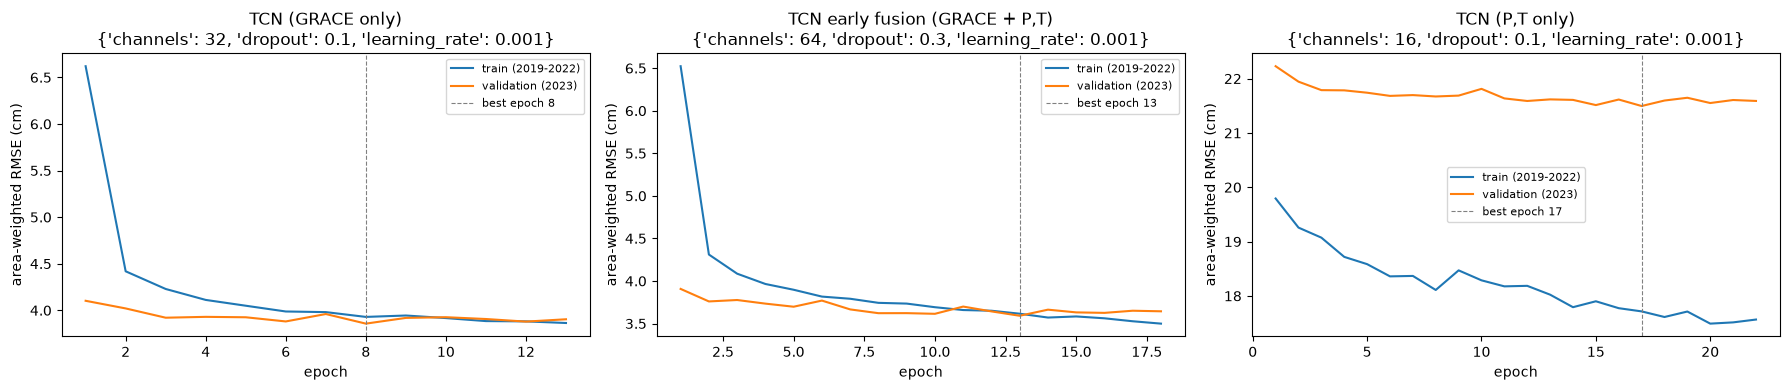

In [11]:
grid_table = pd.DataFrame([{k: v for k, v in r.items() if k != "history"}
                           for e in experiments.values() for r in e["grid"]])
display(grid_table.pivot_table(index=["channels", "dropout", "learning_rate"], columns="run",
                               values="val_rmse_cm").round(3))
selected = pd.DataFrame({label: {**e["params"], "refit_epochs": e["best_epoch"],
                                 "val_rmse_cm": min(r["val_rmse_cm"] for r in e["grid"])}
                         for label, e in experiments.items()}).T
display(selected)
fig = tcn.plot_learning_curves(list(experiments.values()))
plt.show()

## 7. Late fusion

The GRACE-only and P/T-only branches were trained separately. Their 2023 forecasts (from the models
trained on 2019–2022) fit the stacking weights by area-weighted least squares; the weights are then
applied to the refit branches. The test period is never used for fitting.

In [12]:
fusion = tcn.late_fusion(cube, list(experiments.values()), config)
display(pd.Series(fusion["coefficients"], name=fusion["label"]).round(3).to_frame())

Late fusion TCN late fusion (GRACE | P,T): intercept_cm=-0.016, weight[TCN (GRACE only)]=0.994, weight[TCN (P,T only)]=0.039, val_rmse_cm_in_sample=3.842


,"TCN late fusion (GRACE | P,T)"
intercept_cm,-0.016
weight[TCN (GRACE only)],0.994
"weight[TCN (P,T only)]",0.039
val_rmse_cm_in_sample,3.842


## 8. Test evaluation against the baselines

All models are scored on the same test cells: the baseline file's `test_eval_mask` (TWS observed at *t*
and *t*−1), intersected with cells where every model has a prediction. Metrics are area-weighted per-cell
means; MSESS is the pooled skill against climatology.

Test cells: 972,825 (months x pixels) in 21 months


,MAE_cm,RMSE_cm,r_area_wtd,anom_r_area_wtd,NSE_median,pct_NSE_pos,n_cells,MSESS_vs_clim
Seasonal persistence,2.347,2.958,0.797,0.618,0.655,88.715,46325.000,0.860
"TCN early fusion (GRACE + P,T)",2.388,3.009,0.787,0.634,0.673,85.716,46325.000,0.854
"TCN late fusion (GRACE | P,T)",2.435,3.062,0.800,0.635,0.657,90.098,46325.000,0.845
TCN (GRACE only),2.478,3.110,0.796,0.629,0.639,88.076,46325.000,0.842
"ARX (P,T,trend,TWS t-1)",2.896,3.482,0.816,0.667,0.592,81.764,46325.000,0.789
Persistence,3.482,4.249,0.742,0.575,0.546,95.883,46325.000,0.636
"LR (P,T) + trend",4.391,5.122,0.700,0.443,0.181,57.079,46325.000,0.514
"Seasonal-trend + GBM (P,T)",5.320,6.017,0.698,0.426,-0.093,47.309,46325.000,0.309
"LR (P,T)",5.500,6.255,0.666,0.385,-0.093,47.374,46325.000,0.141
Seasonal + trend,5.814,6.564,0.640,0.229,-0.189,43.499,46325.000,0.136


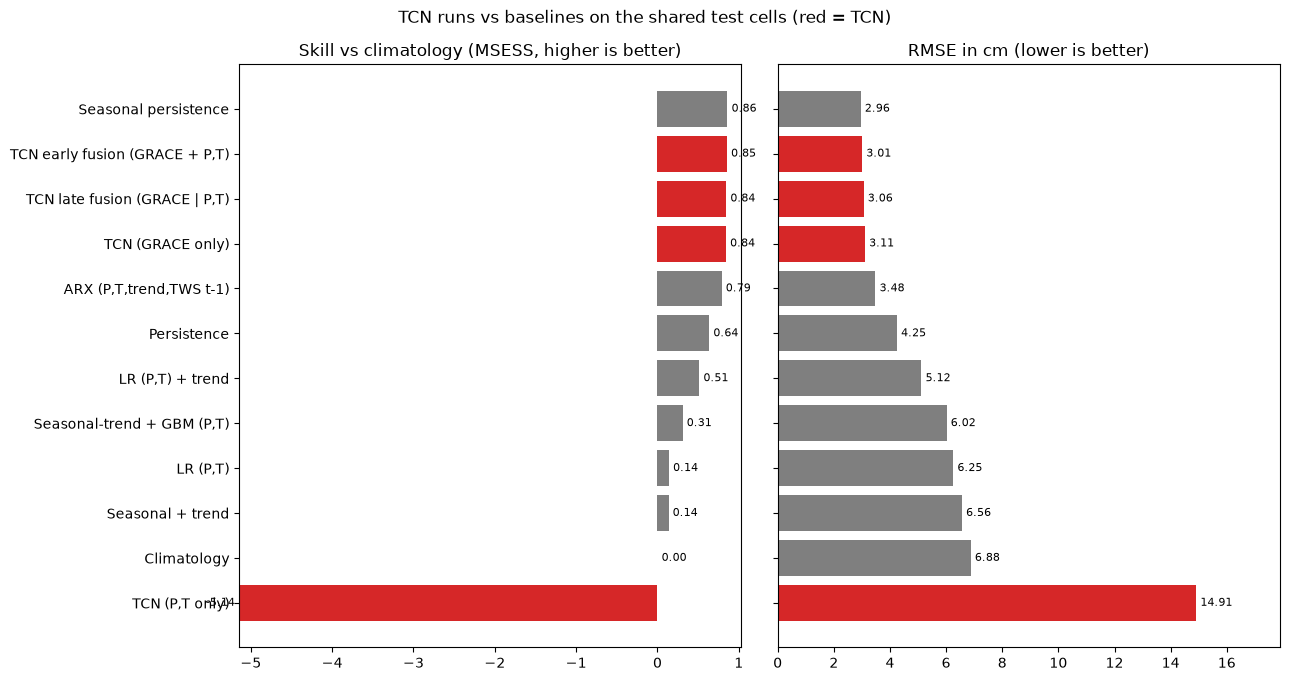

In [13]:
predictions = {label: e["prediction"] for label, e in experiments.items()}
predictions[fusion["label"]] = fusion["prediction"]
tcn_predictions = dict(predictions)

names_path = METRICS_DIR / "p_t_tws_baseline_metrics_gracefo.csv"
names = list(pd.read_csv(names_path, index_col=0).index) if names_path.is_file() else None
baseline_predictions, shared_mask = tcn.load_baseline_predictions(BASELINE_PREDICTIONS, cube, names)
predictions.update(baseline_predictions)

metrics, test_mask = tcn.score_models(cube, predictions, config, shared_mask)
display(metrics.style.format(precision=3).apply(
    lambda row: ["background-color: #fde2e1" if row.name in tcn_predictions else "" for _ in row], axis=1))
fig = tcn.plot_comparison(metrics, list(tcn_predictions))
plt.show()

### Fusion comparison

In [14]:
grace_only, early, late, drivers = list(config["runs"])[0], list(config["runs"])[1], fusion["label"], list(config["runs"])[2]
focus = metrics.loc[[grace_only, early, late, drivers, "Seasonal persistence"],
                    ["RMSE_cm", "MAE_cm", "anom_r_area_wtd", "MSESS_vs_clim"]]
focus["ΔRMSE vs GRACE-only (cm)"] = focus["RMSE_cm"] - metrics.loc[grace_only, "RMSE_cm"]
display(focus.round(3))
for label in (early, late):
    change = metrics.loc[label, "RMSE_cm"] - metrics.loc[grace_only, "RMSE_cm"]
    print(f"{label}: RMSE {'lower' if change < 0 else 'higher'} than GRACE-only by {abs(change):.3f} cm")
best = min((early, late), key=lambda label: metrics.loc[label, "RMSE_cm"])
gap = metrics.loc[best, "RMSE_cm"] - metrics.loc["Seasonal persistence", "RMSE_cm"]
print(f"Best fusion strategy: {best}; vs seasonal persistence: {gap:+.3f} cm RMSE")

,RMSE_cm,MAE_cm,anom_r_area_wtd,MSESS_vs_clim,ΔRMSE vs GRACE-only (cm)
TCN (GRACE only),3.110,2.478,0.629,0.842,0.000
"TCN early fusion (GRACE + P,T)",3.009,2.388,0.634,0.854,-0.101
"TCN late fusion (GRACE | P,T)",3.062,2.435,0.635,0.845,-0.048
"TCN (P,T only)",14.913,13.546,0.190,-5.144,11.803
Seasonal persistence,2.958,2.347,0.618,0.860,-0.152


TCN early fusion (GRACE + P,T): RMSE lower than GRACE-only by 0.101 cm
TCN late fusion (GRACE | P,T): RMSE lower than GRACE-only by 0.048 cm
Best fusion strategy: TCN early fusion (GRACE + P,T); vs seasonal persistence: +0.051 cm RMSE


### Where do precipitation and temperature help?

Per-cell test RMSE change relative to the GRACE-only TCN. Blue = the fusion model is more accurate there.

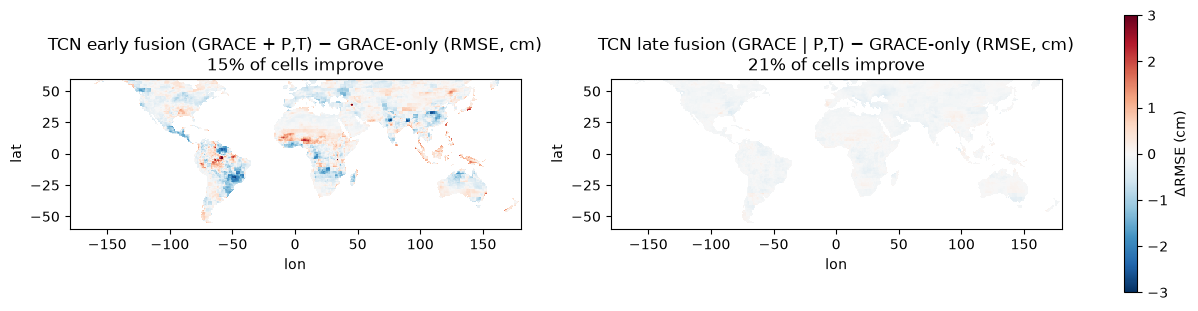

In [15]:
rows_all = cube.split_rows(config["base"]["splits"])
climatology = alignment.monthly_climatology(cube.tws, rows_all["train"] | rows_all["validation"], cube.month)
min_months = config["base"]["baselines"]["min_evaluation_months"]


def rmse_map(label):
    _, maps = tcn.evaluate_predictions(cube.tws, predictions[label], test_mask, cube.area_weight, cube.month,
                                       climatology, min_months=min_months)
    return maps["rmse"]


reference = rmse_map(grace_only)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, label in zip(axes, (early, late)):
    difference = cube.to_map(rmse_map(label) - reference)
    image = ax.pcolormesh(difference.lon, difference.lat, difference, cmap="RdBu_r", vmin=-3, vmax=3, shading="auto")
    better = float(np.nanmean(difference.values < 0) * 100)
    ax.set(title=f"{label} − GRACE-only (RMSE, cm)\n{better:.0f}% of cells improve", xlabel="lon", ylabel="lat")
    ax.set_aspect("equal")
fig.colorbar(image, ax=axes, shrink=0.8, label="ΔRMSE (cm)")
plt.show()

## 9. Save outputs

In [16]:
if QUICK_RUN:
    print("QUICK_RUN: smoke test only, outputs not saved.")
else:
    grid_table.to_csv(METRICS_DIR / "tcn_grid_search.csv", index=False)
    metrics.to_csv(METRICS_DIR / "tcn_test_metrics.csv")
    for label, experiment in experiments.items():
        stem = "tcn_" + "_".join(experiment["sources"])
        torch.save(experiment["model"].state_dict(), MODELS_DIR / f"{stem}.pt")
        (MODELS_DIR / f"{stem}.json").write_text(
            json.dumps(tcn.specification(experiment, config, ALIGNED_FILE.relative_to(PROJECT_ROOT)), indent=2, default=str) + "\n")
    (MODELS_DIR / "tcn_late_fusion.json").write_text(json.dumps(
        {"model": fusion["label"], "branches": fusion["branches"], "combiner": "area-weighted linear stacking",
         "fit_on": "validation predictions of the train-only branch models", **fusion["coefficients"]}, indent=2) + "\n")
    dataset = tcn.prediction_dataset(cube, tcn_predictions, test_mask, config["data"]["timing"])
    dataset.to_netcdf(PREDICTIONS_FILE, engine="netcdf4", encoding=compressed_float_encoding(dataset))
    save_figure(tcn.plot_comparison(metrics, list(tcn_predictions)), FIGURES_DIR / "tcn_01_comparison.png")
    save_figure(tcn.plot_learning_curves(list(experiments.values())), FIGURES_DIR / "tcn_02_learning_curves.png")
    plt.close("all")
    print("Saved metrics, models, predictions and figures.")

Saved metrics, models, predictions and figures.


## 10. Do environmental variables improve forecasting?

This section tests whether adding precipitation and temperature (P, T) gives better TWS forecasts, and where
the gain comes from. It reads the saved predictions (`data/processed/tcn_predictions.nc` and the baseline
predictions), so it runs without retraining: run the setup and configuration cells (1–4), then this section.

**Comparisons.** Each pair is the same model with and without P, T:

* TCN: GRACE-only → early fusion, and GRACE-only → late fusion.
* Baselines: seasonal + trend → LR(P,T) + trend, and persistence → ARX(P,T, trend, TWS *t*−1).

**Method.** All models are scored on the same test cell-months, with RMSE pooled over cells and
area-weighted by cos(latitude). This pooled RMSE weights large-error cells more than the per-cell average in
Section 8, so the values differ, but the comparisons go the same way. The 95% interval for each RMSE change
comes from a moving-block bootstrap over test months (blocks of 3 months, 5,000 resamples), because errors in
consecutive months are correlated.

In [17]:
T0, T1 = "2024-01-01", "2025-09-30"
with xr.open_dataset(PREDICTIONS_FILE) as f:
    tcn_saved = f.sel(time=slice(T0, T1)).load()
with xr.open_dataset(BASELINE_PREDICTIONS) as f:
    base_saved = f.sel(time=slice(T0, T1)).load()
with xr.open_dataset(ALIGNED_FILE) as f:
    train_period = f[["tws_anom", "precip_anom"]].sel(time=slice(*(config["base"]["splits"]["train"][k] for k in ("start", "end"))))
    tws_sd = train_period.tws_anom.std("time").values            # cell variability (training period only)
    precip_sd = train_period.precip_anom.std("time").values
    precip_anom_test = f.precip_anom.sel(time=slice(T0, T1)).values

env_models = {
    "GRACE only": tcn_saved["pred_TCN__GRACE_only"].values,
    "Early fusion": tcn_saved["pred_TCN_early_fusion__GRACE___P_T"].values,
    "Late fusion": tcn_saved["pred_TCN_late_fusion__GRACE___P_T"].values,
    "Seasonal + trend": base_saved["pred_Seasonal___trend"].values,
    "LR(P,T) + trend": base_saved["pred_LR__P_T____trend"].values,
    "Persistence": base_saved["pred_Persistence"].values,
    "ARX(P,T, trend)": base_saved["pred_ARX__P_T_trend_TWS_t_1"].values,
    "Seasonal persistence": base_saved["pred_Seasonal_persistence"].values,
}
obs = tcn_saved.tws_obs.values
valid = (tcn_saved.test_eval_mask.values > 0) & (base_saved.test_eval_mask.values > 0) & np.isfinite(obs)
for values in env_models.values():
    valid &= np.isfinite(values)
sq_err = {name: np.where(valid, (values - obs) ** 2, np.nan) for name, values in env_models.items()}
lat_weight = np.broadcast_to(np.cos(np.deg2rad(tcn_saved.lat.values))[:, None], obs.shape[1:])
sample_weight = np.where(valid, lat_weight, 0.0)
cells = valid.any(0)
test_months = pd.to_datetime(tcn_saved.time.values)
print(f"Test months: {len(test_months)} ({test_months[0]:%Y-%m} … {test_months[-1]:%Y-%m}) | cells: {cells.sum():,} "
      f"| cell-months: {valid.sum():,}")

Test months: 21 (2024-01 … 2025-09) | cells: 46,325 | cell-months: 972,825


In [18]:
rng = np.random.default_rng(0)


def pooled_rmse(name, subset=True):
    weight = sample_weight * subset
    return float(np.sqrt(np.nansum(sq_err[name] * weight) / weight.sum()))


def monthly_mse(name):
    return np.nansum(sq_err[name] * sample_weight, axis=(1, 2)) / sample_weight.sum((1, 2))


def cell_rmse(name):
    return np.sqrt(np.nanmean(sq_err[name], axis=0))


def paired_test(without, with_, block=3, n_boot=5000):
    a, b = monthly_mse(without), monthly_mse(with_)
    n = len(a)
    boots = []
    for _ in range(n_boot):
        starts = rng.integers(0, n - block + 1, size=int(np.ceil(n / block)))
        idx = np.concatenate([np.arange(s, s + block) for s in starts])[:n]
        boots.append(np.sqrt(b[idx].mean()) - np.sqrt(a[idx].mean()))
    low, high = np.percentile(boots, [2.5, 97.5])
    ra, rb = cell_rmse(without), cell_rmse(with_)
    both = cells & np.isfinite(ra) & np.isfinite(rb)
    rmse_a, rmse_b = np.sqrt(a.mean()), np.sqrt(b.mean())
    return {"RMSE without (cm)": rmse_a, "RMSE with (cm)": rmse_b, "ΔRMSE (cm)": rmse_b - rmse_a,
            "Δ%": (rmse_b - rmse_a) / rmse_a * 100, "95% CI low": low, "95% CI high": high,
            "significant": high < 0 or low > 0, "months better": f"{(b < a).sum()}/{n}",
            "% area improved": (lat_weight * (rb < ra) * both).sum() / (lat_weight * both).sum() * 100}


pairs = {
    "TCN: GRACE-only → early fusion": ("GRACE only", "Early fusion"),
    "TCN: GRACE-only → late fusion": ("GRACE only", "Late fusion"),
    "Baseline: seasonal+trend → LR(P,T)+trend": ("Seasonal + trend", "LR(P,T) + trend"),
    "Baseline: persistence → ARX(P,T, trend)": ("Persistence", "ARX(P,T, trend)"),
    "Reference: seasonal persistence → early fusion": ("Seasonal persistence", "Early fusion"),
}
env_tests = pd.DataFrame({label: paired_test(*pair) for label, pair in pairs.items()}).T
display(env_tests.style.format({c: "{:.3f}" for c in env_tests.columns[:3]} | {"Δ%": "{:+.1f}", "95% CI low": "{:+.3f}",
                                "95% CI high": "{:+.3f}", "% area improved": "{:.1f}"}))

,RMSE without (cm),RMSE with (cm),ΔRMSE (cm),Δ%,95% CI low,95% CI high,significant,months better,% area improved
TCN: GRACE-only → early fusion,3.810,3.667,-0.144,-3.8,-0.265,-0.015,True,14/21,57.7
TCN: GRACE-only → late fusion,3.810,3.767,-0.043,-1.1,-0.049,-0.034,True,20/21,76.4
"Baseline: seasonal+trend → LR(P,T)+trend",8.909,6.680,-2.230,-25.0,-2.588,-1.925,True,21/21,69.9
"Baseline: persistence → ARX(P,T, trend)",5.778,4.398,-1.381,-23.9,-1.826,-0.879,True,18/21,57.3
Reference: seasonal persistence → early fusion,3.585,3.667,0.082,+2.3,-0.053,+0.285,False,7/21,45.5


### Where does early fusion help?

The early-fusion gain broken down four ways: by latitude zone, by how variable each cell's water storage and
rainfall were in the training period (terciles), and by how unusual the current month's rainfall is
(|precipitation anomaly| in training standard deviations). Negative Δ% means adding P, T lowered the error.

In [19]:
abs_lat = np.abs(np.broadcast_to(tcn_saved.lat.values[:, None], obs.shape[1:]))
ref_cell, fus_cell = cell_rmse("GRACE only"), cell_rmse("Early fusion")
comparable = cells & np.isfinite(ref_cell) & np.isfinite(fus_cell)


def breakdown_row(group, label, subset, cell_subset=None):
    g, e = pooled_rmse("GRACE only", subset), pooled_rmse("Early fusion", subset)
    row = {"breakdown": group, "group": label, "% of samples": (sample_weight * subset).sum() / sample_weight.sum() * 100,
           "GRACE-only RMSE": g, "Early-fusion RMSE": e, "ΔRMSE (cm)": e - g, "Δ%": (e - g) / g * 100}
    if cell_subset is not None:
        sel = comparable & cell_subset
        row["% area improved"] = (lat_weight * (fus_cell < ref_cell) * sel).sum() / (lat_weight * sel).sum() * 100
    return row


rows_where = []
for label, zone in {"Tropics (|lat| < 23.5°)": abs_lat < 23.5, "Subtropics (23.5–40°)": (abs_lat >= 23.5) & (abs_lat < 40),
                    "Mid/high latitudes (≥ 40°)": abs_lat >= 40}.items():
    rows_where.append(breakdown_row("Latitude zone", label, zone[None], zone))
for group, values in {"TWS variability": tws_sd, "Precipitation variability": precip_sd}.items():
    q1, q2 = np.nanpercentile(values[cells], [100 / 3, 200 / 3])
    for label, sel in {"low": values < q1, "mid": (values >= q1) & (values < q2), "high": values >= q2}.items():
        rows_where.append(breakdown_row(group + " (tercile)", label, sel[None], sel))
z = np.abs(precip_anom_test) / precip_sd[None]
for low, high in [(0, 0.5), (0.5, 1), (1, 2), (2, np.inf)]:
    label = f"{low}–{high} σ" if np.isfinite(high) else f"> {low} σ"
    rows_where.append(breakdown_row("|Precip anomaly at t|", label, (z >= low) & (z < high)))
env_breakdown = pd.DataFrame(rows_where).set_index(["breakdown", "group"])
display(env_breakdown.style.format(precision=2, na_rep="–").format({"Δ%": "{:+.1f}", "ΔRMSE (cm)": "{:+.3f}"}))

monthly_env = pd.DataFrame({name: np.sqrt(monthly_mse(name)) for name in ("GRACE only", "Early fusion", "Seasonal persistence")},
                           index=test_months)

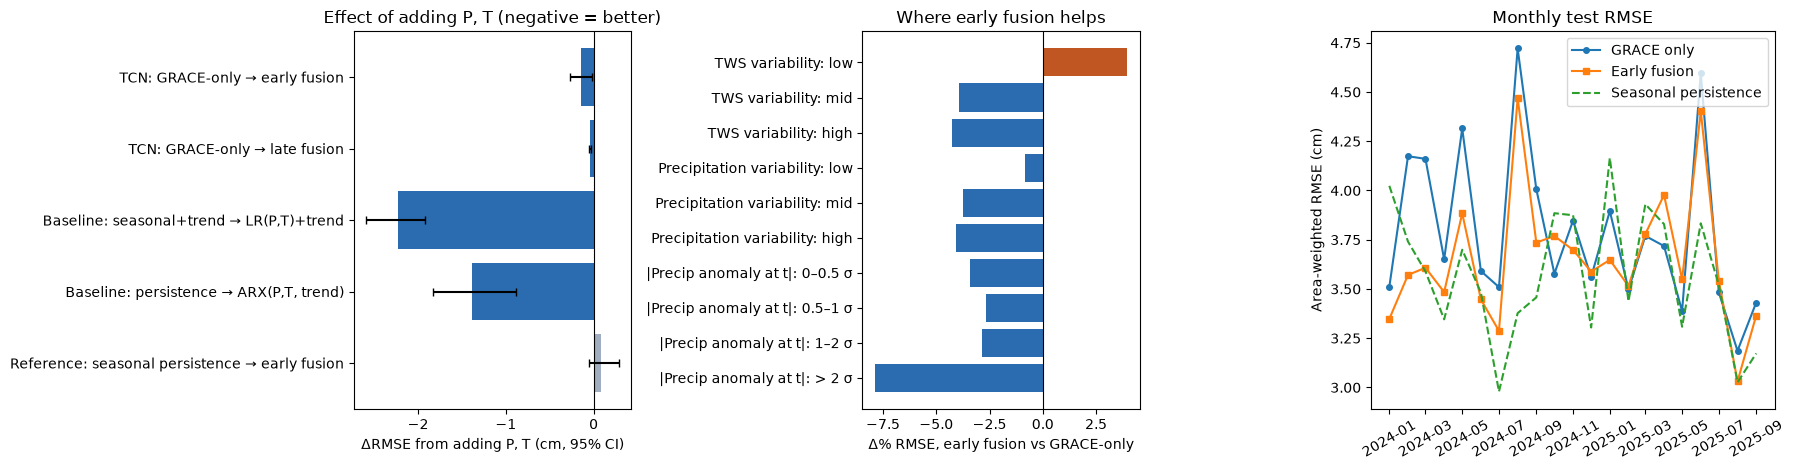

Saved tcn_environmental_value_tests.csv, tcn_environmental_value_breakdown.csv and tcn_03_environmental_value.png


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1.1, 1.1, 1.6]})

ax = axes[0]
ci = env_tests[["ΔRMSE (cm)", "95% CI low", "95% CI high"]].astype(float).iloc[::-1]
colors = ["#2b6cb0" if h < 0 else "#a0aec0" for h in ci["95% CI high"]]
ax.barh(ci.index, ci["ΔRMSE (cm)"], color=colors,
        xerr=[ci["ΔRMSE (cm)"] - ci["95% CI low"], ci["95% CI high"] - ci["ΔRMSE (cm)"]], capsize=3)
ax.axvline(0, color="k", lw=0.8)
ax.set(xlabel="ΔRMSE from adding P, T (cm, 95% CI)", title="Effect of adding P, T (negative = better)")

ax = axes[1]
plot_rows = env_breakdown.drop(index="Latitude zone", level=0)
labels = [f"{b.split(' (')[0]}: {g}" for b, g in plot_rows.index]
ax.barh(labels[::-1], plot_rows["Δ%"].values[::-1],
        color=["#2b6cb0" if v < 0 else "#c05621" for v in plot_rows["Δ%"].values[::-1]])
ax.axvline(0, color="k", lw=0.8)
ax.set(xlabel="Δ% RMSE, early fusion vs GRACE-only", title="Where early fusion helps")

ax = axes[2]
for name, style in {"GRACE only": "-o", "Early fusion": "-s", "Seasonal persistence": "--"}.items():
    ax.plot(monthly_env.index, monthly_env[name], style, label=name, ms=4)
ax.set(ylabel="Area-weighted RMSE (cm)", title="Monthly test RMSE")
ax.legend()
ax.tick_params(axis="x", labelrotation=30)
fig.tight_layout()
plt.show()

if not QUICK_RUN:
    env_tests.to_csv(METRICS_DIR / "tcn_environmental_value_tests.csv")
    env_breakdown.to_csv(METRICS_DIR / "tcn_environmental_value_breakdown.csv")
    save_figure(fig, FIGURES_DIR / "tcn_03_environmental_value.png")
    print("Saved tcn_environmental_value_tests.csv, tcn_environmental_value_breakdown.csv and tcn_03_environmental_value.png")

### Conclusion

*(Numbers are from the full run on 2026-11-23. If the models are retrained, check them against the tables above.)*

**Short answer: yes, weather data helps, but only a little.** When we give the TCN precipitation and
temperature alongside its GRACE history (early fusion), its test error drops by about 3.8% (0.14 cm). That
is small, but it isn't noise: the 95% interval stays below zero (−0.27 to −0.02 cm), early fusion wins in 14
of the 21 test months, and it improves about 58% of the land area. On the per-cell metric from Section 8,
RMSE goes from 3.11 to 3.01 cm.

**Why so small?** The TCN already sees twelve months of water-storage history, and most of what can be
predicted about next month is already in that history. For the simple baselines, which have no recent
storage data to lean on, adding precipitation and temperature cuts error by about 25%. For the TCN they are
a refinement, not a breakthrough.

**Where they help most** is where you would expect weather to matter. In months with unusually heavy or light
rain (more than 2σ from normal), error falls by about 8%, compared with about 3% in ordinary months. The
gain is also larger in places where rainfall and storage vary a lot (about 4%) and in the subtropics (about
7%). In the calmest regions, where storage barely changes, the extra inputs slightly hurt.

**Late fusion was disappointing.** Combining a GRACE-only model with a separate weather-only model improved
error by only about 1%. The weather-only branch could not learn on its own, because without any storage input
it has no idea what each cell's normal water level is. So it ended up with almost no weight (about 0.04).
That points to a weakness in how that branch was set up, not to a lack of information in the weather data.

**Bottom line:** neither fused TCN significantly beats seasonal persistence, our strongest baseline. Weather
inputs make a good GRACE-based forecast slightly better, but they don't change the overall picture.

## 11. Which inputs drive the predictions? Integrated Gradients

**Integrated Gradients (IG)** (Sundararajan et al., 2017) splits one forecast among its inputs. It compares
the real input window *x* with a reference window *x′* and adds up the model's gradients along the straight
path from *x′* to *x*:

$$\text{IG}_i(x) = (x_i - x'_i)\int_0^1 \frac{\partial F\big(x' + \alpha (x - x')\big)}{\partial x_i}\,d\alpha .$$

Each input value (a variable at one month of the window) gets a contribution in **cm of TWS**. The
contributions add up exactly to *F(x) − F(x′)*, the difference between the forecast and the reference
forecast. This is the **completeness** property, and it is checked below.

**Reference: average conditions.** In the reference window, TWS is at the training mean and the
precipitation and temperature anomalies are zero (normal weather). The GRACE observed flag and the month
features keep their real values, so they are context and get no attribution. The attributions therefore
answer: *how much did each variable, in each past month, move this forecast away from the forecast for
average conditions?* Because each cell's typical TWS level differs from the global mean, past TWS is
expected to dominate. The interesting questions are how much weight precipitation and temperature still
get, and which months matter.

**Setup.** The saved refit models (`models/tcn_tws_precip_t2m.pt` = early fusion, `models/tcn_tws.pt` =
GRACE-only) are explained on the same random sample of 20,000 test windows (2024-01 … 2025-09, observed
targets), using 64 integration steps. Averages are area-weighted by cos(latitude). Importance is the mean
absolute attribution. **Lag** counts months before the target month *t*: with nowcast timing the window holds
TWS at lags 12 … 1 and P/T at lags 11 … 0.

This section only needs the setup and configuration cells (1–4) and the saved models; no retraining.

In [21]:
IG_SAMPLES, IG_STEPS = (2_000, 16) if QUICK_RUN else (20_000, 64)
VARIABLE_NAMES = {"tws_prev": "Past TWS (GRACE)", "precip_anom": "Precipitation anomaly", "t2m_anom": "Temperature anomaly"}

with xr.open_dataset(ALIGNED_FILE) as aligned:
    ig_cube = alignment.PixelCube.from_dataset(aligned.assign(mask=aligned[config["data"]["cell_mask"]]))
ig_rows = ig_cube.split_rows(config["base"]["splits"])
lookback = config["data"]["lookback_months"]
test_time, test_pixel = tcn.sample_index(ig_rows["test"], ig_cube.tws, lookback)
pick = np.sort(np.random.default_rng(42).choice(len(test_time), size=min(IG_SAMPLES, len(test_time)), replace=False))
ig_time, ig_pixel = test_time[pick], test_pixel[pick]
ig_weight = ig_cube.area_weight[ig_pixel]
print(f"Explaining {len(pick):,} of {len(test_time):,} test windows "
      f"({ig_cube.times[ig_time.min()]:%Y-%m} … {ig_cube.times[ig_time.max()]:%Y-%m}), {IG_STEPS} integration steps")

ig_runs = {"TCN early fusion (GRACE + P,T)": "tcn_tws_precip_t2m.json", "TCN (GRACE only)": "tcn_tws.json"}
ig = {}
for label, spec_file in ig_runs.items():
    model, spec = tcn.load_trained_model(MODELS_DIR / spec_file)
    data = tcn.explanation_inputs(ig_cube, spec, config)
    x = data.windows(torch.from_numpy(ig_time), torch.from_numpy(ig_pixel))
    del data
    baseline = tcn.average_conditions_baseline(x, spec["input_channels"])
    started = time.time()
    attributions, gaps = tcn.integrated_gradients(model, x, baseline, steps=IG_STEPS)
    scale = spec["scaling_train_validation"]["tws_std_cm"]
    with torch.no_grad():
        delta = (model(x) - model(baseline)).numpy() * scale
    names = spec["input_channels"]
    ig[label] = {"names": names, "attr_cm": attributions.numpy() * scale, "gap_cm": gaps.numpy() * scale,
                 "delta_cm": delta, "x": x.numpy(), "lags": tcn.attribution_lags(names, lookback)}
    print(f"{label}: {time.time() - started:.0f} s | mean |F(x) − F(reference)| = {np.abs(delta).mean():.2f} cm | "
          f"mean |completeness gap| = {np.abs(gaps.numpy() * scale).mean():.4f} cm "
          f"({np.abs(gaps.numpy() * scale).mean() / np.abs(delta).mean() * 100:.2f}% of the explained change)")
del x, baseline, attributions

Explaining 20,000 of 972,825 test windows (2024-01 … 2025-09), 64 integration steps


TCN early fusion (GRACE + P,T): 225 s | mean |F(x) − F(reference)| = 13.35 cm | mean |completeness gap| = 0.0163 cm (0.12% of the explained change)


TCN (GRACE only): 163 s | mean |F(x) − F(reference)| = 13.59 cm | mean |completeness gap| = 0.0126 cm (0.09% of the explained change)


### Which input variables matter most?

For each window the attribution of a variable is summed over its 12 window months. The **share** is that
variable's part of the total absolute attribution. The **net contribution** is the mean absolute value of
the summed (signed) attribution, i.e. how far the variable moves a typical forecast, in cm.

In [22]:
def weighted_mean(values, weight=None):
    weight = ig_weight if weight is None else weight
    return float(np.sum(values * weight) / np.sum(weight))


def per_variable(result):
    rows = {}
    for index, name in enumerate(result["names"]):
        if name not in tcn.ATTRIBUTED_CHANNELS:
            continue
        attr = result["attr_cm"][:, :, index]
        rows[VARIABLE_NAMES[name]] = {"abs_total": weighted_mean(np.abs(attr).sum(1)),
                                      "net_cm": weighted_mean(np.abs(attr.sum(1)))}
    table = pd.DataFrame(rows).T
    table["share_%"] = table["abs_total"] / table["abs_total"].sum() * 100
    return table


variable_importance = pd.concat({label: per_variable(result) for label, result in ig.items()}, names=["model", "variable"])
variable_importance = variable_importance.rename(columns={"abs_total": "mean Σ|attribution| (cm)",
                                                          "net_cm": "mean |net contribution| (cm)",
                                                          "share_%": "share of attribution (%)"})
display(variable_importance.round(3))

mean Σ|attribution| (cm)  \
model                          variable                                          
TCN early fusion (GRACE + P,T) Past TWS (GRACE)                         17.200   
                               Precipitation anomaly                     1.283   
                               Temperature anomaly                       1.032   
TCN (GRACE only)               Past TWS (GRACE)                         19.684   

                                                      mean |net contribution| (cm)  \
model                          variable                                              
TCN early fusion (GRACE + P,T) Past TWS (GRACE)                             13.516   
                               Precipitation anomaly                         0.655   
                               Temperature anomaly                           0.482   
TCN (GRACE only)               Past TWS (GRACE)                             13.743   

                                                      share of attribution (%)  
model                          variable                                         
TCN early fusion (GRACE + P,T) Past TWS (GRACE)                         88.138  
                               Precipitation anomaly                     6.575  
                               Temperature anomaly                       5.287  
TCN (GRACE only)               Past TWS (GRACE)                        100.000

### Which past months matter most?

Mean absolute attribution of each variable at each lag. Lag 1 for TWS is the most recent GRACE month
(*t*−1); lag 0 for precipitation and temperature is the target month itself (nowcast timing).

In [23]:
lag_rows = []
for label, result in ig.items():
    for index, name in enumerate(result["names"]):
        if name not in tcn.ATTRIBUTED_CHANNELS:
            continue
        importance = (np.abs(result["attr_cm"][:, :, index]) * ig_weight[:, None]).sum(0) / ig_weight.sum()
        for step, lag in enumerate(result["lags"][name]):
            lag_rows.append({"model": label, "variable": VARIABLE_NAMES[name], "lag_months": int(lag),
                             "mean_abs_attribution_cm": importance[step]})
lag_importance = pd.DataFrame(lag_rows)
display(lag_importance.pivot_table(index="lag_months", columns=["model", "variable"],
                                   values="mean_abs_attribution_cm").round(3))

for label in ig:
    tws = lag_importance[(lag_importance.model == label) & (lag_importance.variable == VARIABLE_NAMES["tws_prev"])].set_index("lag_months")
    share = tws.mean_abs_attribution_cm / tws.mean_abs_attribution_cm.sum() * 100
    print(f"{label}: TWS attribution from lag 1 = {share.loc[1]:.0f}%, lags 1–3 = {share.loc[[1, 2, 3]].sum():.0f}%, "
          f"lags 10–12 = {share.loc[[10, 11, 12]].sum():.0f}%")
for name in ("precip_anom", "t2m_anom"):
    rows_ = lag_importance[(lag_importance.model == list(ig)[0]) & (lag_importance.variable == VARIABLE_NAMES[name])].set_index("lag_months")
    share = rows_.mean_abs_attribution_cm / rows_.mean_abs_attribution_cm.sum() * 100
    print(f"Early fusion, {VARIABLE_NAMES[name]}: lag 0 = {share.loc[0]:.0f}%, lags 0–2 = {share.loc[[0, 1, 2]].sum():.0f}%")

model      TCN (GRACE only) TCN early fusion (GRACE + P,T)  \
variable   Past TWS (GRACE)               Past TWS (GRACE)   
lag_months                                                   
0                       NaN                            NaN   
1                    12.739                         11.702   
2                     0.669                          0.201   
3                     1.180                          0.850   
4                     0.172                          0.108   
5                     0.524                          0.448   
6                     0.089                          0.043   
7                     0.329                          0.205   
8                     0.041                          0.035   
9                     1.097                          1.412   
10                    0.429                          0.260   
11                    2.170                          1.858   
12                    0.246                          0.077   

model                                                 
variable   Precipitation anomaly Temperature anomaly  
lag_months                                            
0                          0.442               0.307  
1                          0.178               0.062  
2                          0.097               0.080  
3                          0.042               0.074  
4                          0.113               0.105  
5                          0.034               0.019  
6                          0.041               0.047  
7                          0.015               0.014  
8                          0.150               0.154  
9                          0.048               0.032  
10                         0.061               0.090  
11                         0.062               0.048  
12                           NaN                 NaN

TCN early fusion (GRACE + P,T): TWS attribution from lag 1 = 68%, lags 1–3 = 74%, lags 10–12 = 13%
TCN (GRACE only): TWS attribution from lag 1 = 65%, lags 1–3 = 74%, lags 10–12 = 14%
Early fusion, Precipitation anomaly: lag 0 = 34%, lags 0–2 = 56%
Early fusion, Temperature anomaly: lag 0 = 30%, lags 0–2 = 44%


### When and how do precipitation and temperature matter?

Two checks on the early-fusion model:

1. **When:** the share of attribution going to precipitation + temperature, by how unusual the target
   month's rainfall is (|anomaly| in units of the cell's training-period standard deviation, as in
   Section 10) and by latitude zone.
2. **Direction:** the mean signed attribution of the target-month (lag 0) anomaly when it is clearly
   positive (> +1σ) or negative (< −1σ). Physically, a wet month should raise the TWS forecast.

In [24]:
early_label = list(ig)[0]
early = ig[early_label]
channel = {name: early["names"].index(name) for name in tcn.ATTRIBUTED_CHANNELS}
abs_attr = np.abs(early["attr_cm"])
weather_share = (abs_attr[:, :, channel["precip_anom"]].sum(1) + abs_attr[:, :, channel["t2m_anom"]].sum(1))
total = sum(abs_attr[:, :, channel[name]].sum(1) for name in tcn.ATTRIBUTED_CHANNELS)

_, train_anomalies = alignment.training_anomalies(ig_cube, ig_rows["train"])
cell_sd = {name: np.nanstd(train_anomalies[name][ig_rows["train"]], axis=0) for name in ("precip", "t2m")}
z = {name: train_anomalies[name][ig_time, ig_pixel] / cell_sd[name][ig_pixel] for name in ("precip", "t2m")}


def share_row(group, label, selected):
    return {"breakdown": group, "group": label, "% of windows": selected.mean() * 100,
            "P+T share of attribution (%)": np.sum(weather_share[selected] * ig_weight[selected]) /
                                            np.sum(total[selected] * ig_weight[selected]) * 100}


rows_when = []
for low, high in [(0, 0.5), (0.5, 1), (1, 2), (2, np.inf)]:
    label = f"{low}–{high} σ" if np.isfinite(high) else f"> {low} σ"
    rows_when.append(share_row("|Precip anomaly at t|", label, (np.abs(z["precip"]) >= low) & (np.abs(z["precip"]) < high)))
abs_lat = np.abs(ig_cube.pixel_lat[ig_pixel])
for label, selected in {"Tropics (|lat| < 23.5°)": abs_lat < 23.5, "Subtropics (23.5–40°)": (abs_lat >= 23.5) & (abs_lat < 40),
                        "Mid/high latitudes (≥ 40°)": abs_lat >= 40}.items():
    rows_when.append(share_row("Latitude zone", label, selected))
rows_when.append(share_row("All", "all test windows", np.ones(len(ig_time), bool)))
weather_when = pd.DataFrame(rows_when).set_index(["breakdown", "group"])
display(weather_when.round(1))

rows_direction = []
for name, short in (("precip_anom", "precip"), ("t2m_anom", "t2m")):
    lag0 = early["attr_cm"][:, -1, channel[name]]
    for label, selected in {"anomaly < −1σ": z[short] < -1, "|anomaly| ≤ 1σ": np.abs(z[short]) <= 1, "anomaly > +1σ": z[short] > 1}.items():
        rows_direction.append({"variable": VARIABLE_NAMES[name], "target-month anomaly": label,
                               "% of windows": selected.mean() * 100,
                               "mean attribution at lag 0 (cm)": weighted_mean(lag0[selected], ig_weight[selected]),
                               "% windows raising forecast": weighted_mean((lag0[selected] > 0).astype(float), ig_weight[selected]) * 100})
weather_direction = pd.DataFrame(rows_direction).set_index(["variable", "target-month anomaly"])
display(weather_direction.round(2))

% of windows  \
breakdown             group                                      
|Precip anomaly at t| 0–0.5 σ                             46.9   
                      0.5–1 σ                             21.6   
                      1–2 σ                               20.6   
                      > 2 σ                               10.9   
Latitude zone         Tropics (|lat| < 23.5°)             35.9   
                      Subtropics (23.5–40°)               29.0   
                      Mid/high latitudes (≥ 40°)          35.1   
All                   all test windows                   100.0   

                                                  P+T share of attribution (%)  
breakdown             group                                                     
|Precip anomaly at t| 0–0.5 σ                                             10.1  
                      0.5–1 σ                                             11.6  
                      1–2 σ                                               13.5  
                      > 2 σ                                               16.0  
Latitude zone         Tropics (|lat| < 23.5°)                             11.6  
                      Subtropics (23.5–40°)                               12.2  
                      Mid/high latitudes (≥ 40°)                          12.0  
All                   all test windows                                    11.9

% of windows  \
variable              target-month anomaly                 
Precipitation anomaly anomaly < −1σ                16.20   
                      |anomaly| ≤ 1σ               68.49   
                      anomaly > +1σ                15.30   
Temperature anomaly   anomaly < −1σ                 9.36   
                      |anomaly| ≤ 1σ               53.94   
                      anomaly > +1σ                36.69   

                                            mean attribution at lag 0 (cm)  \
variable              target-month anomaly                                   
Precipitation anomaly anomaly < −1σ                                  -0.61   
                      |anomaly| ≤ 1σ                                  0.01   
                      anomaly > +1σ                                   1.25   
Temperature anomaly   anomaly < −1σ                                   0.41   
                      |anomaly| ≤ 1σ                                 -0.01   
                      anomaly > +1σ                                  -0.31   

                                            % windows raising forecast  
variable              target-month anomaly                              
Precipitation anomaly anomaly < −1σ                               9.07  
                      |anomaly| ≤ 1σ                             41.66  
                      anomaly > +1σ                              98.60  
Temperature anomaly   anomaly < −1σ                              83.69  
                      |anomaly| ≤ 1σ                             47.58  
                      anomaly > +1σ                              24.96

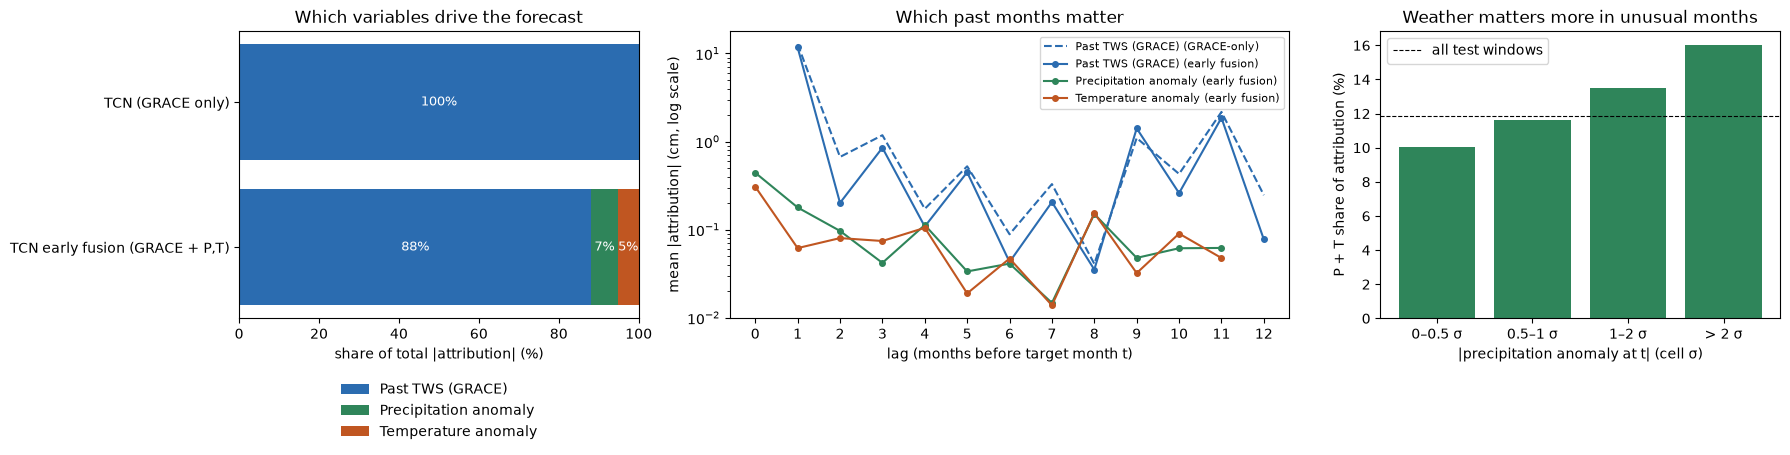

Saved tcn_ig_variable_importance.csv, tcn_ig_lag_importance.csv, tcn_ig_weather_conditions.csv and tcn_04_integrated_gradients.png


In [25]:
colors = {VARIABLE_NAMES["tws_prev"]: "#2b6cb0", VARIABLE_NAMES["precip_anom"]: "#2f855a", VARIABLE_NAMES["t2m_anom"]: "#c05621"}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1, 1.4, 1]})

ax = axes[0]
shares = variable_importance["share of attribution (%)"].unstack("variable").reindex(columns=list(colors)).fillna(0)
left = np.zeros(len(shares))
for variable in shares.columns:
    ax.barh(shares.index, shares[variable], left=left, color=colors[variable], label=variable)
    for y, (l, v) in enumerate(zip(left, shares[variable])):
        if v >= 4:
            ax.text(l + v / 2, y, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9)
    left += shares[variable].values
ax.set(xlabel="share of total |attribution| (%)", xlim=(0, 100), title="Which variables drive the forecast")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=1, frameon=False)

ax = axes[1]
for (label, variable), group in lag_importance.groupby(["model", "variable"]):
    group = group.sort_values("lag_months")
    style = "-o" if label == early_label else "--"
    ax.plot(group.lag_months, group.mean_abs_attribution_cm, style, color=colors[variable], ms=4,
            label=f"{variable} ({'early fusion' if label == early_label else 'GRACE-only'})")
ax.set(yscale="log", xlabel="lag (months before target month t)", ylabel="mean |attribution| (cm, log scale)",
       title="Which past months matter", xticks=range(0, 13))
ax.legend(fontsize=8)

ax = axes[2]
when = weather_when.loc["|Precip anomaly at t|"]
ax.bar(when.index, when["P+T share of attribution (%)"], color=colors[VARIABLE_NAMES["precip_anom"]])
ax.axhline(weather_when.loc[("All", "all test windows"), "P+T share of attribution (%)"], color="k", lw=0.8, ls="--",
           label="all test windows")
ax.set(xlabel="|precipitation anomaly at t| (cell σ)", ylabel="P + T share of attribution (%)",
       title="Weather matters more in unusual months")
ax.legend()
fig.tight_layout()
plt.show()

if not QUICK_RUN:
    variable_importance.to_csv(METRICS_DIR / "tcn_ig_variable_importance.csv")
    lag_importance.to_csv(METRICS_DIR / "tcn_ig_lag_importance.csv", index=False)
    pd.concat({"when": weather_when.reset_index(), "direction": weather_direction.reset_index()}).to_csv(
        METRICS_DIR / "tcn_ig_weather_conditions.csv")
    save_figure(fig, FIGURES_DIR / "tcn_04_integrated_gradients.png")
    print("Saved tcn_ig_variable_importance.csv, tcn_ig_lag_importance.csv, tcn_ig_weather_conditions.csv "
          "and tcn_04_integrated_gradients.png")

### Conclusion

**First, a sanity check.** Integrated Gradients is supposed to split each forecast exactly among its
inputs, and here it does: the attributions add up to the change in the forecast to within about 0.1%. So the
numbers below can be trusted as an accounting of what the model uses.

**The model mostly relies on past water storage.** In the early-fusion model, past GRACE storage accounts for
about 88% of the attribution, precipitation 7% and temperature 5%. Put another way, storage history moves a
typical forecast by about 13.5 cm, compared with about 0.7 cm for precipitation and 0.5 cm for temperature.
Part of this is simply that every cell has its own typical storage level, which the model reads from the
history. This fits Section 10: GRACE carries the forecast, and weather adjusts it.

**Recent months matter most.** Last month's storage alone accounts for about two-thirds of the storage
attribution (68%), and the last three months about 74%. There is a smaller bump around 9–11 months back,
which suggests the model also uses last year's seasonal pattern. For weather, the target month itself counts
most (about a third of the precipitation and temperature attribution), and the effect of rain fades over the
following two to three months, much as rainfall soaks into storage gradually.

**The model's reasoning is physically sensible.** A wet month pushes the forecast up in 99% of cases (by about
1.25 cm on average), and a dry month pulls it down (about −0.61 cm). A warm month lowers the forecast (about
−0.31 cm), as you would expect from more evaporation, and a cold month raises it (about +0.41 cm). In other
words, the network has picked up the basic water balance, not some odd shortcut.

**It also pays more attention to weather when weather is unusual.** The weather share grows from about 10%
in ordinary months to 16% in months with extreme rainfall. These are the same months where Section 10 found
the biggest accuracy gains, which is reassuring: the model leans on weather when weather actually tells it
something new.

**Adding weather makes the model lean slightly less on storage history** (total storage attribution drops
from 19.7 to 17.2 cm), but the shape over time stays almost the same.

**A note of caution on the lag chart.** The zigzag, where odd lags get more weight than their neighbours,
comes from how the dilated convolutions are wired, not from hydrology. Most layers can only connect months
an even distance apart, so some months are easier for the network to reach than others. Read the chart as
"recent months versus about a year back", not month by month. Also, these attributions are measured against
average conditions; using each cell's normal seasonal cycle as the reference would give storage history a
smaller share.